# Episode 9: Gradient Descent, Part 1
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2009%20-%20Gradient%20Descent%2C%20Part%201/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*. Gradient Descent, part 1 of 2: the learning rate, by hand.

The episode works every calculation by hand. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. It uses only `numpy` and `matplotlib` (both already in Colab), plus Python's built-in `fractions` so the thirds and ninths print exactly: choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | The update rule θ ← θ − η ∇L, one step on Episode 6's bowl, and steps that shrink by themselves | 3 → 1.36 · 3 → 19 |
| 2 | The one-knob valley κz²: the factor 1 − 2ηκ, six learning rates, the zones, and how many steps | 0.8, 0.64, 0.512 · 0.5 · 0 · −0.5 · −1 · −1.5 · 228 / 7 / 1 ≈ 2.3/η |
| 3 | The bowl z₁² + 2z₂²: two factors, the limit 0.5, the best repeated step 1/3, and a race against 0.278 | 1.36 · 2, 2, 2 · 19, 163, 1459 · 2.334, 2.721 · 3/9ᵏ · 5 steps |
| 4 | Stretched bowls (50 to 1, and Episode 7's three dots) and mat's surprisal, a loss with no bottom | 0.961, 116 · ≈ 46 to 1, 0.958, ≈ 107 · 0.315, 0.463, 0.934 |
| 5 | The myth: "a smaller learning rate is always safer" | 228 vs 7 · best step 1/3 |
| 6 | The check question | η < 1/3 · 0.4, 0.48 · η = 1/6 |
| 7 | Try it yourself, with self-checks | your numbers |

The valleys and bowls are exact quadratics, so every sequence here is exact arithmetic (up to floating-point rounding). Mat's probabilities are **illustrative** (Episode 5's R = 0.70). The steepness is **κ** (kappa) and the learning rate is **η** (eta). Goodfellow et al. write the learning rate with another Greek letter; this series uses η, like Ruder.

## Setup

In [1]:
from fractions import Fraction as F

import matplotlib.pyplot as plt
import numpy as np

STEEL, GOLD, CORAL, MUTED = "#8FB4E8", "#FFC400", "#FF4D3D", "#8B98AE"   # the video's colours
DOT = "#1B2A4A"                                                          # the walker (white on the video's navy)


def fmt(x):
    """Print a number the way you would write it on paper: 0.64, not 0.6400000000000001."""
    return f"{round(float(x), 8):.10g}"


def descend(z0, eta, kappa=1.0, steps=3):
    """Gradient descent on the valley f(z) = kappa z^2 (slope 2 kappa z). Returns [z0, z1, ..., z_steps]."""
    zs = [z0]
    for _ in range(steps):
        z = zs[-1]
        zs.append(z - eta * 2 * kappa * z)
    return zs


def bowl(z1, z2):
    """Episode 6's bowl: f = z1^2 + 2 z2^2."""
    return z1 ** 2 + 2 * z2 ** 2


def bowl_grad(z1, z2):
    return np.array([2 * z1, 4 * z2])


def bowl_walk(eta, steps=3, start=(1.0, 1.0)):
    """Repeat the rule on the bowl. Returns the list of points and the list of heights."""
    pts = [np.array(start, dtype=float)]
    for _ in range(steps):
        pts.append(pts[-1] - eta * bowl_grad(*pts[-1]))
    return pts, [bowl(*p) for p in pts]

## Part 1 · The rule

### Step 1: the update rule, piece by piece
**θ ← θ − η ∇_θ L(θ)**

- **θ** is all the knobs.
- **∇_θ L(θ)**, the gradient, is the list of slopes, one per knob. It points uphill the fastest (Episode 6).
- The **minus sign** turns us around, so we walk downhill.
- **η** (eta) is the learning rate: how far to go. Goodfellow, Bengio and Courville: "a positive scalar determining the size of the step".

Then repeat, until the gradient is zero or very close.

Episode 6 took one step on the bowl f = z₁² + 2z₂², starting at (1, 1), height 3. Here it is again, with the rule written out.

In [2]:
start = np.array([1.0, 1.0])
print(f"start (1, 1): height {fmt(bowl(*start))};  gradient (2 z1, 4 z2) = {bowl_grad(*start)}")
for eta in (0.1, 1.0):
    new = start - eta * bowl_grad(*start)
    print(f"eta = {fmt(eta)}:  (1, 1) - {fmt(eta)} x (2, 4) = ({fmt(new[0])}, {fmt(new[1])})   height {fmt(bowl(*new))}")
assert bowl(*start) == 3
assert np.isclose(bowl(*(start - 0.1 * bowl_grad(*start))), 1.36)
assert np.isclose(bowl(*(start - 1.0 * bowl_grad(*start))), 19)
print("Same direction, different stride: down to 1.36, or up to 19.")

start (1, 1): height 3;  gradient (2 z1, 4 z2) = [2. 4.]
eta = 0.1:  (1, 1) - 0.1 x (2, 4) = (0.8, 0.6)   height 1.36
eta = 1:  (1, 1) - 1 x (2, 4) = (-1, -3)   height 19
Same direction, different stride: down to 1.36, or up to 19.


### Step 2: steps shrink by themselves near the bottom
The step is η × slope. Near the bottom the ground flattens, the slope shrinks, and so does the step, even though η never changes. Here is the valley f(z) = z² (slope 2z) with a fixed η = 0.1.

In [3]:
zs = descend(1.0, 0.1, steps=6)
step_sizes = [abs(b - a) for a, b in zip(zs, zs[1:])]
for k, (z, s) in enumerate(zip(zs, step_sizes)):
    print(f"at z = {z:.4f}: slope {2 * z:.4f},  step = 0.1 x slope = {s:.4f}")
assert all(b < a for a, b in zip(step_sizes, step_sizes[1:]))        # every step smaller than the one before
assert np.allclose(step_sizes, [0.1 * 2 * z for z in zs[:-1]])        # step = eta x slope
print("Same eta every time; the steps still shrink as the walker arrives.")

at z = 1.0000: slope 2.0000,  step = 0.1 x slope = 0.2000
at z = 0.8000: slope 1.6000,  step = 0.1 x slope = 0.1600
at z = 0.6400: slope 1.2800,  step = 0.1 x slope = 0.1280
at z = 0.5120: slope 1.0240,  step = 0.1 x slope = 0.1024
at z = 0.4096: slope 0.8192,  step = 0.1 x slope = 0.0819
at z = 0.3277: slope 0.6554,  step = 0.1 x slope = 0.0655
Same eta every time; the steps still shrink as the walker arrives.


### Step 3: why η needs care
Ruder's survey of gradient descent names both failures: too small leads to "painfully slow convergence"; too large can make the loss fluctuate "or even to diverge". 3Blue1Brown describes it as overshooting and oscillating. Parts 2 and 3 watch both happen, by hand.

## Part 2 · A valley with one knob

### Step 4: the valley and its slope
**f(z) = κz²**, with κ > 0 the steepness. The bottom is at z = 0. Episode 5: the slope of z² is 2z, so the slope of κz² is **2κz**.

In [4]:
eps = 1e-6
for kappa in (1, 3):
    for z in (-1.5, 0.3, 1.0, 2.0):
        numeric = (kappa * (z + eps) ** 2 - kappa * (z - eps) ** 2) / (2 * eps)
        assert np.isclose(numeric, 2 * kappa * z)
print("slope of kappa z^2 = 2 kappa z (checked numerically for kappa = 1 and 3)")

slope of kappa z^2 = 2 kappa z (checked numerically for kappa = 1 and 3)


### Step 5: one step, slowly, and the factor
new z = z − η · 2κz = **(1 − 2ηκ) · z**

Both terms have a z, so pull it out. The bracket **1 − 2ηκ** is the factor. Since the bottom is at 0, z is the distance from the bottom, and every step multiplies it by the same factor. After k steps:

**z_k = (1 − 2ηκ)^k · z₀**

In [5]:
rng = np.random.default_rng(9)
for _ in range(200):                                  # any kappa, eta, start: one step = factor x z
    kappa, eta, z0 = rng.uniform(0.1, 5), rng.uniform(0.01, 2), rng.uniform(-3, 3)
    factor = 1 - 2 * eta * kappa
    assert np.isclose(descend(z0, eta, kappa, 1)[1], factor * z0)
    assert np.isclose(descend(z0, eta, kappa, 7)[7], factor ** 7 * z0)
print("new z = (1 - 2 eta kappa) z, and after k steps z_k = factor^k z0: checked on 200 random cases.")
print("factor 0.8: every step keeps 80% of the distance and removes 20%.")

new z = (1 - 2 eta kappa) z, and after k steps z_k = factor^k z0: checked on 200 random cases.
factor 0.8: every step keeps 80% of the distance and removes 20%.


### Step 6: six learning rates, by hand
κ = 1, start at z = 1.

In [6]:
cases = {0.1: [0.8, 0.64, 0.512], 0.25: [0.5, 0.25, 0.125], 0.5: [0, 0, 0],
         0.75: [-0.5, 0.25, -0.125], 1.0: [-1, 1, -1], 1.25: [-1.5, 2.25, -3.375]}
labels = {0.1: "slides in slowly (hiker 1)", 0.25: "halves every step", 0.5: "lands in one step (hiker 3)",
          0.75: "hops sides, shrinks", 1.0: "bounces forever", 1.25: "diverges (hiker 2)"}
seqs = {}
for eta, expected in cases.items():
    factor = 1 - 2 * eta
    seq = descend(1.0, eta, 1.0, 3)
    seqs[eta] = seq
    print(f"eta = {fmt(eta):<5} factor = 1 - 2 x {fmt(eta)} = {fmt(factor):<5}  z: " +
          ", ".join(fmt(z) for z in seq) + f"   {labels[eta]}")
    assert np.allclose(seq[1:], expected)
assert np.isclose(descend(1.0, 0.1, 1.0, 4)[4], 0.4096)
print("\nwhy eta = 0.5 lands in one step: slope at z = 1 is 2;  0.5 x 2 = 1 = the distance to the bottom")
assert 0.5 * 2 * 1 == 1

eta = 0.1   factor = 1 - 2 x 0.1 = 0.8    z: 1, 0.8, 0.64, 0.512   slides in slowly (hiker 1)
eta = 0.25  factor = 1 - 2 x 0.25 = 0.5    z: 1, 0.5, 0.25, 0.125   halves every step
eta = 0.5   factor = 1 - 2 x 0.5 = 0      z: 1, 0, 0, 0   lands in one step (hiker 3)
eta = 0.75  factor = 1 - 2 x 0.75 = -0.5   z: 1, -0.5, 0.25, -0.125   hops sides, shrinks
eta = 1     factor = 1 - 2 x 1 = -1     z: 1, -1, 1, -1   bounces forever
eta = 1.25  factor = 1 - 2 x 1.25 = -1.5   z: 1, -1.5, 2.25, -3.375   diverges (hiker 2)

why eta = 0.5 lands in one step: slope at z = 1 is 2;  0.5 x 2 = 1 = the distance to the bottom


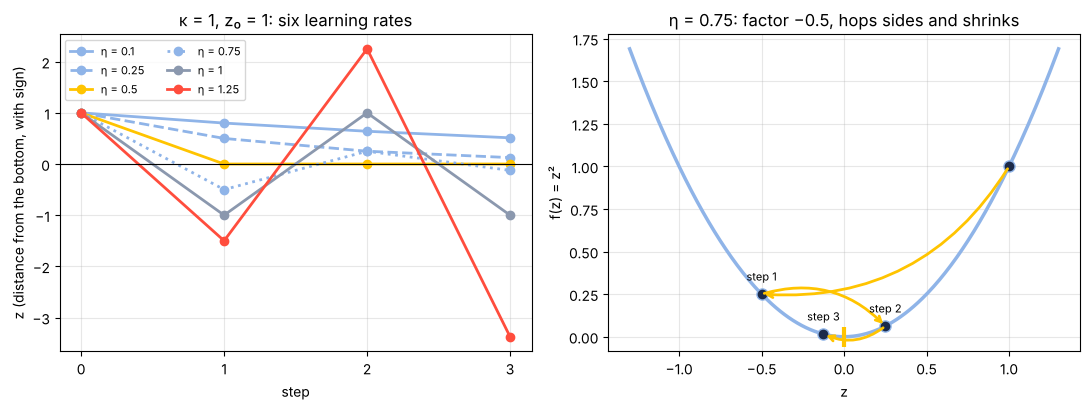

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
colours = {0.1: STEEL, 0.25: STEEL, 0.5: GOLD, 0.75: STEEL, 1.0: MUTED, 1.25: CORAL}
styles = {0.1: "-", 0.25: "--", 0.5: "-", 0.75: ":", 1.0: "-", 1.25: "-"}
for eta in cases:
    ax.plot(range(4), seqs[eta], styles[eta], marker="o", color=colours[eta], lw=2, label=f"η = {fmt(eta)}")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(4)); ax.set_xlabel("step"); ax.set_ylabel("z (distance from the bottom, with sign)")
ax.set_title("κ = 1, z₀ = 1: six learning rates"); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)

ax = axes[1]                                          # the walker on the valley, eta = 0.75
zz = np.linspace(-1.3, 1.3, 300)
ax.plot(zz, zz ** 2, color=STEEL, lw=2.5)
seq = descend(1.0, 0.75, 1.0, 3)
for k, (a, b) in enumerate(zip(seq, seq[1:])):
    ax.annotate("", (b, b ** 2), (a, a ** 2), arrowprops=dict(arrowstyle="->", color=GOLD, lw=2,
                                                            connectionstyle="arc3,rad=-0.3"))
    ax.text(b, b ** 2 + 0.08, f"step {k + 1}", ha="center", fontsize=8)
ax.plot(seq, [z ** 2 for z in seq], "o", color=DOT, mec=STEEL, ms=8)
ax.plot([0], [0], "|", color=GOLD, ms=14, mew=3)
ax.set_xlabel("z"); ax.set_ylabel("f(z) = z²"); ax.set_title("η = 0.75: factor −0.5, hops sides and shrinks")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 7: the zones on one number line
| η | factor 1 − 2ηκ | what happens |
|---|---|---|
| 0 < η < 1/(2κ) | between 0 and 1 | slides in from one side |
| η = 1/(2κ) | 0 | lands in one step |
| 1/(2κ) < η < 1/κ | between −1 and 0 | hops and shrinks |
| η = 1/κ | −1 | bounces forever |
| η > 1/κ | below −1 | blows up |

Gradient descent settles exactly when **0 < η < 1/κ**.

For kappa = 1, 3 and 0.5, the zone predicted by the factor matches the walk every time.
kappa = 1, eta = 0.1  : slides in
kappa = 1, eta = 0.25 : slides in
kappa = 1, eta = 0.5  : one step
kappa = 1, eta = 0.75 : hops and shrinks
kappa = 1, eta = 1    : bounces
kappa = 1, eta = 1.25 : blows up
settles exactly when 0 < eta < 1/kappa


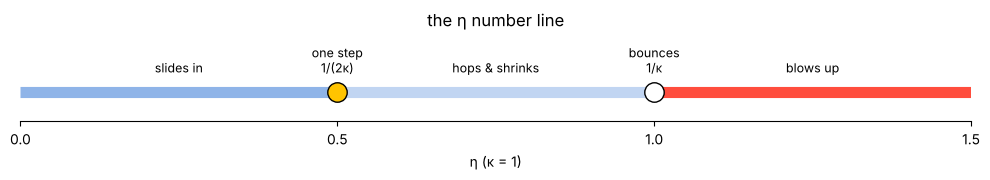

In [8]:
def zone(eta, kappa):
    """Which zone eta is in, from the factor alone."""
    f = 1 - 2 * eta * kappa
    if np.isclose(f, 0):
        return "one step"
    if np.isclose(f, -1):
        return "bounces"
    if 0 < f < 1:
        return "slides in"
    if -1 < f < 0:
        return "hops and shrinks"
    return "blows up"


def behaviour(eta, kappa, steps=60):
    """What the walk actually does, from z0 = 1."""
    zs = np.array(descend(1.0, eta, kappa, steps))
    if abs(zs[1]) < 1e-12:
        return "one step"
    if np.allclose(np.abs(zs), 1):
        return "bounces"
    if abs(zs[-1]) > 1:
        return "blows up"
    return "slides in" if np.all(zs > 0) else "hops and shrinks"


for kappa in (1, 3, 0.5):
    for frac in (0.2, 0.5, 0.7, 1.0, 1.1):            # eta as a fraction of 1/kappa
        eta = frac / kappa
        assert zone(eta, kappa) == behaviour(eta, kappa), (kappa, eta)
print("For kappa = 1, 3 and 0.5, the zone predicted by the factor matches the walk every time.")
for eta in cases:
    print(f"kappa = 1, eta = {fmt(eta):<5}: {zone(eta, 1)}")
settles = [eta for eta in np.linspace(0.01, 2, 200) if abs(descend(1.0, eta, 1.0, 200)[-1]) < 1e-3]
assert 0 < min(settles) and max(settles) < 1
print("settles exactly when 0 < eta < 1/kappa")

fig, ax = plt.subplots(figsize=(10, 1.9))
ax.plot([0, 0.5], [0, 0], color=STEEL, lw=8, solid_capstyle="butt")
ax.plot([0.5, 1], [0, 0], color=STEEL, lw=8, alpha=0.55, solid_capstyle="butt")
ax.plot([1, 1.5], [0, 0], color=CORAL, lw=8, solid_capstyle="butt")
ax.plot([0.5], [0], "o", color=GOLD, ms=14, mec="black")
ax.plot([1], [0], "o", color="white", ms=14, mec="black")
for x, t in [(0.25, "slides in"), (0.5, "one step\n1/(2κ)"), (0.75, "hops & shrinks"), (1, "bounces\n1/κ"), (1.25, "blows up")]:
    ax.text(x, 0.35, t, ha="center", va="bottom", fontsize=9)
ax.set_xlim(0, 1.5); ax.set_ylim(-0.6, 1.2); ax.set_yticks([])
ax.set_xticks([0, 0.5, 1, 1.5]); ax.set_xlabel("η (κ = 1)")
ax.set_title("the η number line"); ax.spines[["left", "right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

### Step 8: how slow is safe?
Count the steps until |z| ≤ 0.01, from z = 1 (κ = 1). For small η the factor is close to 1, and the count is roughly **ln 100 / (2η) ≈ 2.3 / η**: ten times smaller η, about ten times more steps.

eta = 0.01   228 steps
eta = 0.25     7 steps
eta = 0.5      1 steps

ln 100 / 2 = 2.303  ->  roughly 2.3 / eta
eta = 0.001: 2301 steps;  2.3 / 0.001 = 2300


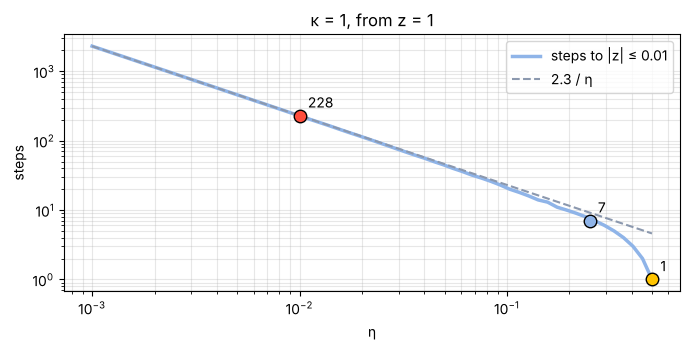

In [9]:
def steps_to(eta, kappa=1.0, tol=0.01, z0=1.0, cap=10 ** 6):
    z, k = z0, 0
    while abs(z) > tol and k < cap:
        z *= 1 - 2 * eta * kappa
        k += 1
    return k


counts = {eta: steps_to(eta) for eta in (0.01, 0.25, 0.5)}
for eta, n in counts.items():
    print(f"eta = {fmt(eta):<5} {n:>4} steps")
assert counts == {0.01: 228, 0.25: 7, 0.5: 1}
print(f"\nln 100 / 2 = {np.log(100) / 2:.3f}  ->  roughly 2.3 / eta")
assert round(np.log(100) / 2, 1) == 2.3
for eta in (0.001, 0.002, 0.005, 0.01):
    assert abs(steps_to(eta) - 2.3 / eta) / (2.3 / eta) < 0.02          # within 2% for small eta
print(f"eta = 0.001: {steps_to(0.001)} steps;  2.3 / 0.001 = {2.3 / 0.001:.0f}")

etas = np.geomspace(0.001, 0.5, 60)
plt.figure(figsize=(7, 3.6))
plt.loglog(etas, [steps_to(e) for e in etas], color=STEEL, lw=2.5, label="steps to |z| ≤ 0.01")
plt.loglog(etas, 2.3 / etas, "--", color=MUTED, label="2.3 / η")
for eta, n in counts.items():
    plt.plot([eta], [n], "o", color=GOLD if eta == 0.5 else CORAL if eta == 0.01 else STEEL, ms=9, mec="black")
    plt.annotate(f"{n}", (eta, n), textcoords="offset points", xytext=(6, 6))
plt.xlabel("η"); plt.ylabel("steps"); plt.title("κ = 1, from z = 1"); plt.grid(alpha=0.3, which="both"); plt.legend()
plt.tight_layout()
plt.show()

## Part 3 · The bowl from Episode 6

### Step 9: each knob gets its own factor
f = z₁² + 2z₂², start (1, 1), height 3. The gradient is (2z₁, 4z₂), so each knob only sees its own slope:

- z₁ is multiplied by **1 − 2η** (κ = 1)
- z₂ is multiplied by **1 − 4η** (κ = 2, twice as steep)

In [10]:
eta = 0.1
f1, f2 = 1 - 2 * eta, 1 - 4 * eta
h1 = f1 ** 2 + 2 * f2 ** 2
print(f"eta = 0.1: factors {fmt(f1)} and {fmt(f2)}")
print(f"height = {fmt(f1)}^2 + 2 x {fmt(f2)}^2 = {fmt(f1 ** 2)} + 2 x {fmt(f2 ** 2)} = {fmt(f1 ** 2)} + {fmt(2 * f2 ** 2)} = {fmt(h1)}")
assert np.isclose(f1, 0.8) and np.isclose(f2, 0.6)
assert np.isclose(f1 ** 2, 0.64) and np.isclose(2 * f2 ** 2, 0.72) and np.isclose(h1, 1.36)
pts, hs = bowl_walk(0.1, 3)
for k in range(4):
    assert np.allclose(pts[k], [f1 ** k, f2 ** k])        # the coordinates separate
print("heights:", ", ".join(fmt(round(h, 3)) for h in hs))
assert [round(h, 3) for h in hs] == [3, 1.36, 0.669, 0.355]
print("Exactly Episode 6's step, then two more.")

eta = 0.1: factors 0.8 and 0.6
height = 0.8^2 + 2 x 0.6^2 = 0.64 + 2 x 0.36 = 0.64 + 0.72 = 1.36
heights: 3, 1.36, 0.669, 0.355
Exactly Episode 6's step, then two more.


### Step 10: the steepest direction sets the speed limit
Both factors must stay smaller than 1 in size: |1 − 2η| < 1 needs η < 1, and |1 − 4η| < 1 needs η < 0.5. The limit is **0.5**, set by the steeper direction.

In [11]:
limit_z1, limit_z2 = 1 / 1, 1 / 2                    # 1/kappa for each direction
limit = min(limit_z1, limit_z2)
print(f"z1 needs eta < {fmt(limit_z1)};  z2 needs eta < {fmt(limit_z2)};  limit = {fmt(limit)}")
assert limit == 0.5

for eta, expected in [(0.5, [3, 2, 2, 2]), (1.0, [3, 19, 163, 1459])]:
    pts, hs = bowl_walk(eta, 3)
    print(f"eta = {fmt(eta)}: z2 = " + ", ".join(fmt(p[1]) for p in pts) + ";  heights " + ", ".join(fmt(h) for h in hs))
    assert np.allclose(hs, expected)
assert np.allclose([p[1] for p in bowl_walk(0.5, 3)[0]], [1, -1, 1, -1])
print("eta = 0.5: z1 lands at 0 in one step, z2 flips between -1 and 1, and the height is stuck at 2.")

z1 needs eta < 1;  z2 needs eta < 0.5;  limit = 0.5
eta = 0.5: z2 = 1, -1, 1, -1;  heights 3, 2, 2, 2
eta = 1: z2 = 1, -3, 9, -27;  heights 3, 19, 163, 1459
eta = 0.5: z1 lands at 0 in one step, z2 flips between -1 and 1, and the height is stuck at 2.


### Step 11: one step versus many
Episode 6 found that **one** step from (1, 1) goes down for any η below 0.556, and that the best single step is about 0.278 (height 0.222). Both are true, for one step. Repeat the step, and the limit drops to 0.5.

In [12]:
one_step = lambda eta: (1 - 2 * eta) ** 2 + 2 * (1 - 4 * eta) ** 2
# one step goes down when 36 eta^2 - 20 eta < 0, i.e. eta < 5/9
print(f"one step goes down for eta < 5/9 = {5 / 9:.3f};  best single step 5/18 = {5 / 18:.3f} -> height {one_step(5 / 18):.3f}")
assert round(5 / 9, 3) == 0.556 and round(5 / 18, 3) == 0.278 and round(one_step(5 / 18), 3) == 0.222
grid = np.linspace(0, 1, 100001)
assert np.isclose(grid[np.argmin(one_step(grid))], 5 / 18, atol=1e-5)
assert np.all(one_step(grid[(grid > 0) & (grid < 5 / 9 - 1e-6)]) < 3)

pts, hs = bowl_walk(0.52, 2)
print(f"eta = 0.52: heights {fmt(hs[0])}, {hs[1]:.3f} (down), {hs[2]:.3f} (back up)")
assert round(hs[1], 3) == 2.334 and round(hs[2], 3) == 2.721 and hs[1] < 3 and hs[2] > hs[1]
assert bowl_walk(0.52, 30)[1][-1] > 100                   # repeated, it blows up
print("The first step looked great. The second gave it back; keep going and it blows up.")

one step goes down for eta < 5/9 = 0.556;  best single step 5/18 = 0.278 -> height 0.222
eta = 0.52: heights 3, 2.334 (down), 2.721 (back up)
The first step looked great. The second gave it back; keep going and it blows up.


### Step 12: the best step if you are going to repeat it
Make both factors the same size: **1 − 2η = −(1 − 4η)**, so 1 − 2η = 4η − 1, 6η = 2, **η = 1/3**. Both factors become 1/3 in size, so every step divides the height by 9: **height = 3/9^k**.

In [13]:
eta_best = F(1, 3)
fz1, fz2 = 1 - 2 * eta_best, 1 - 4 * eta_best
print(f"eta = {eta_best}: factors {fz1} and {fz2}  (same size)")
assert fz1 == -fz2 == F(1, 3)
exact = [(fz1 ** k) ** 2 + 2 * (fz2 ** k) ** 2 for k in range(4)]
print("heights: " + ", ".join(str(h) for h in exact) + "  =  " + ", ".join(f"{float(h):.3f}" for h in exact[1:]))
assert exact == [F(3, 9 ** k) for k in range(4)]
assert [round(float(h), 3) for h in exact[1:]] == [0.333, 0.037, 0.004]
pts, hs = bowl_walk(1 / 3, 6)
assert np.allclose(hs, [3 / 9 ** k for k in range(7)])
within = next(k for k, p in enumerate(pts) if np.all(np.abs(p) <= 0.01))
print(f"both knobs within 0.01 of the bottom after {within} steps  ((1/3)^4 = {float(F(1, 3) ** 4):.4f}, (1/3)^5 = {float(F(1, 3) ** 5):.4f})")
assert within == 5
etas = np.linspace(0.01, 0.49, 4801)
worst = np.maximum(np.abs(1 - 2 * etas), np.abs(1 - 4 * etas))     # the slower knob's factor
assert np.isclose(etas[np.argmin(worst)], 1 / 3, atol=1e-4)
print("No other eta has a smaller worst factor: 1/3 is the best repeated step.")

eta = 1/3: factors 1/3 and -1/3  (same size)
heights: 3, 1/3, 1/27, 1/243  =  0.333, 0.037, 0.004
both knobs within 0.01 of the bottom after 5 steps  ((1/3)^4 = 0.0123, (1/3)^5 = 0.0041)
No other eta has a smaller worst factor: 1/3 is the best repeated step.


### Step 13: the race, 0.278 against 1/3
Episode 6's best single step starts faster, but by step 2 it is behind, and by step 3 it is about twice as high.

step   eta = 0.278   eta = 1/3   leader
   1       0.2222      0.3333   0.278
   2       0.0392      0.0370   1/3
   3       0.0077      0.0041   1/3
   4       0.0015      0.0005   1/3
   5       0.0003      0.0001   1/3


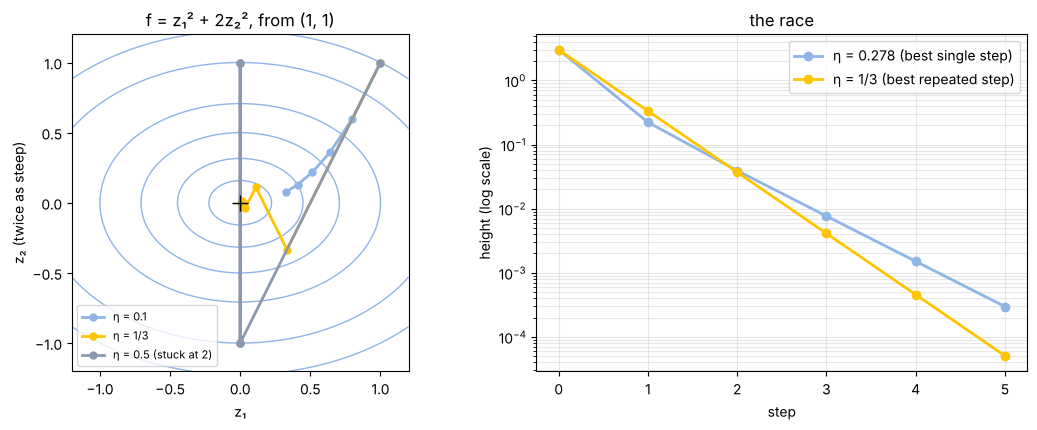

In [14]:
_, race_a = bowl_walk(0.278, 5)
_, race_b = bowl_walk(1 / 3, 5)
print("step   eta = 0.278   eta = 1/3   leader")
for k in range(1, 6):
    lead = "0.278" if race_a[k] < race_b[k] else "1/3"
    print(f"{k:>4}   {race_a[k]:>10.4f}   {race_b[k]:>9.4f}   {lead}")
assert [round(h, 3) for h in race_a[1:4]] == [0.222, 0.039, 0.008]
assert race_a[1] < race_b[1] and race_a[2] > race_b[2] and race_a[3] > race_b[3]
assert round(race_a[3], 3) == 0.008 and round(race_b[3], 3) == 0.004 and 1.8 < race_a[3] / race_b[3] < 2
assert all(race_a[k] > race_b[k] for k in range(2, 6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
ax.contour(g1, g2, bowl(g1, g2), levels=[0.05, 0.2, 0.5, 1, 2, 3], colors=STEEL, linewidths=1)
for eta, col, lab in [(0.1, STEEL, "η = 0.1"), (1 / 3, GOLD, "η = 1/3"), (0.5, MUTED, "η = 0.5 (stuck at 2)")]:
    p = np.array(bowl_walk(eta, 5)[0])
    ax.plot(p[:, 0], p[:, 1], "-o", color=col, lw=2, ms=5, label=lab)
ax.plot([0], [0], "+", color="black", ms=12)
ax.set_aspect("equal"); ax.set_xlabel("z₁"); ax.set_ylabel("z₂ (twice as steep)")
ax.set_title("f = z₁² + 2z₂², from (1, 1)"); ax.legend(fontsize=8, loc="lower left")
ax = axes[1]
ax.semilogy(range(6), race_a, "-o", color=STEEL, lw=2, label="η = 0.278 (best single step)")
ax.semilogy(range(6), race_b, "-o", color=GOLD, lw=2, label="η = 1/3 (best repeated step)")
ax.set_xlabel("step"); ax.set_ylabel("height (log scale)"); ax.set_title("the race"); ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

## Part 4 · Stretched bowls, and a loss with no bottom

### Step 14: a bowl stretched 50 to 1
For f = z₁² + κ z₂² the best repeated step makes the two factors equal in size, η = 1/(1 + κ), and the factor is **(κ − 1)/(κ + 1)**. Check: κ = 2 gives 1/3. With κ = 50 it is 49/51.

In [15]:
def best_factor(k_small, k_big):
    """Best repeated step on a bowl with steepnesses k_small and k_big: equal-size factors."""
    eta = 1 / (k_small + k_big)
    return eta, (k_big - k_small) / (k_big + k_small)


def steps_for(factor, shrink=0.01):
    return int(np.ceil(np.log(shrink) / np.log(factor)))


assert np.isclose(best_factor(1, 2)[1], 1 / 3)
eta50, fac50 = best_factor(1, 50)
n50 = steps_for(fac50)
print(f"z1^2 + 50 z2^2: best eta = 1/51, factor 49/51 = {fac50:.3f};  {n50} steps to shrink the distance 100-fold")
assert round(fac50, 3) == 0.961 and n50 == 116
z = np.array([1.0, 1.0])
for k in range(n50):
    z = z - eta50 * np.array([2 * z[0], 100 * z[1]])
assert np.all(np.abs(z) <= 0.01)                       # ... and walking it confirms the count

z1^2 + 50 z2^2: best eta = 1/51, factor 49/51 = 0.961;  116 steps to shrink the distance 100-fold


### Step 15: Episode 7's three dots are a stretched bowl too
Episode 7's loss for the dots (1, 2), (2, 4), (3, 5) is the mean squared error of ŷ = Wu + β. As a function of (W, β) it is a tilted, stretched bowl. Its steepness in each of its two main directions comes from the curvature matrix (the Hessian, for the curious): **f = κz²** has curvature 2κ, so each κ is half an eigenvalue.

kappa along the two main directions: 5.546 and 0.1202  (about 5.55 and 0.120)
stretched about 46 to 1;  best factor 0.958;  106.2 -> about 107 steps
Goodfellow et al.: ill-conditioning can cause SGD to get "stuck".


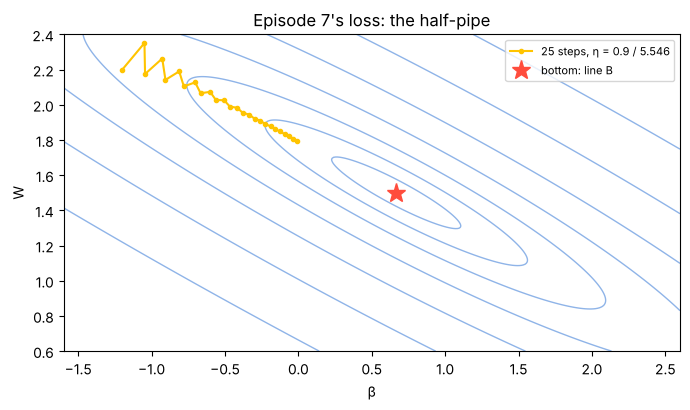

In [16]:
u = np.array([1, 2, 3]); y = np.array([2, 4, 5]); N = len(u)
X = np.column_stack([u, np.ones(N)])
H = 2 / N * X.T @ X                                   # curvature of the MSE in (W, beta)
kappas = np.sort(np.linalg.eigvalsh(H) / 2)
ratio = kappas[1] / kappas[0]
eta7, fac7 = best_factor(*kappas)
n7 = np.log(0.01) / np.log(fac7)
print(f"kappa along the two main directions: {kappas[1]:.3f} and {kappas[0]:.4f}  (about 5.55 and 0.120)")
print(f"stretched about {ratio:.0f} to 1;  best factor {fac7:.3f};  {n7:.1f} -> about {int(np.ceil(n7))} steps")
assert round(kappas[1], 3) == 5.546 and round(kappas[0], 4) == 0.1202 and round(ratio) == 46
assert round(fac7, 3) == 0.958 and int(np.ceil(n7)) == 107

mse = lambda W, b: ((y - (W * u + b)) ** 2).mean()   # check: MSE minus its minimum is a bowl with these kappas
Wstar, bstar = 1.5, 2 / 3
for dW, db in [(0.3, -0.2), (-1, 0.5), (0.05, 0.9)]:
    d = np.array([dW, db])
    assert np.isclose(mse(Wstar + dW, bstar + db) - mse(Wstar, bstar), 0.5 * d @ H @ d)
print('Goodfellow et al.: ill-conditioning can cause SGD to get "stuck".')

fig, ax = plt.subplots(figsize=(7, 4.2))             # the half-pipe: zig-zag across, creep along
Wg, bg = np.meshgrid(np.linspace(0.6, 2.4, 300), np.linspace(-1.6, 2.6, 300))
M = ((y[None, None, :] - (Wg[..., None] * u + bg[..., None])) ** 2).mean(axis=-1)
ax.contour(bg, Wg, M, levels=np.geomspace(0.02, 6, 9), colors=STEEL, linewidths=1)
p = np.array([2.2, -1.2]); path = [p]
eta_hp = 0.9 / kappas[1]                              # a "modest" eta: 90% of the walls' limit
for _ in range(25):
    r = y - (p[0] * u + p[1])
    p = p - eta_hp * np.array([-2 * (r * u).mean(), -2 * r.mean()])
    path.append(p)
path = np.array(path)
ax.plot(path[:, 1], path[:, 0], "-o", color=GOLD, ms=3, lw=1.5, label="25 steps, η = 0.9 / 5.546")
ax.plot([bstar], [Wstar], "*", color=CORAL, ms=14, label="bottom: line B")
ax.set_xlabel("β"); ax.set_ylabel("W"); ax.set_title("Episode 7's loss: the half-pipe"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
assert mse(*path[-1]) > mse(Wstar, bstar) + 0.01      # still not at the bottom after 25 steps

### Step 16: not every loss is a bowl, mat's surprisal
Episode 5: mat has score z, the other candidates have total weight R = 0.70, so p(mat) = eᶻ / (eᶻ + R). The loss is mat's surprisal L = −ln p, and its slope with respect to the score is −(1 − p), which is **−0.70** at the start (p = 0.30). So each step raises the score by 0.70 × η (the rule: z ← z − η × (−0.70)).

eta = 0.1  score +0.07:  p(mat) 0.30 -> 0.315 (loss 1.155);  after 10 steps 0.447 (loss 0.806)
eta = 1    score +0.70:  p(mat) 0.30 -> 0.463 (loss 0.770);  after 10 steps 0.894 (loss 0.112)
eta = 5    score +3.50:  p(mat) 0.30 -> 0.934 (loss 0.068);  after 10 steps 0.984 (loss 0.016)
Bigger eta was faster in every run checked (eta from 0.01 to 1000, 1 and 10 steps). No bottom to fly past.


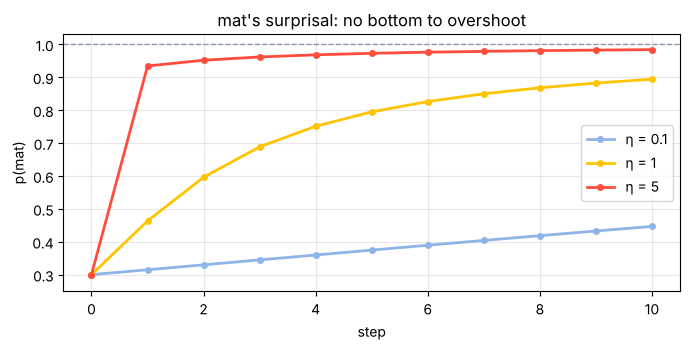

In [17]:
R = 0.70


def p_mat(z):
    return np.exp(z) / (np.exp(z) + R)


def mat_walk(eta, steps):
    z = np.log(0.30)                                   # start: p(mat) = 0.30
    ps = [p_mat(z)]
    for _ in range(steps):
        slope = -(1 - p_mat(z))                        # Episode 5: dL/dz = -(1 - p)
        z = z - eta * slope
        ps.append(p_mat(z))
    return ps


assert np.isclose(p_mat(np.log(0.30)), 0.30) and np.isclose(-(1 - 0.30), -0.70)
zc, e = np.log(0.30), 1e-6
assert np.isclose((-np.log(p_mat(zc + e)) + np.log(p_mat(zc - e))) / (2 * e), -0.70)
expected1 = {0.1: 0.315, 1: 0.463, 5: 0.934}
expected10 = {0.1: 0.447, 1: 0.894, 5: 0.984}
for eta in (0.1, 1, 5):
    ps = mat_walk(eta, 10)
    print(f"eta = {fmt(eta):<4} score +{0.70 * eta:.2f}:  p(mat) 0.30 -> {ps[1]:.3f} (loss {-np.log(ps[1]):.3f});  after 10 steps {ps[10]:.3f} (loss {-np.log(ps[10]):.3f})")
    assert round(ps[1], 3) == expected1[eta] and round(ps[10], 3) == expected10[eta]
    assert all(b > a for a, b in zip(ps, ps[1:])) and ps[-1] < 1    # loss always falls, never reaches 0
assert [round(-np.log(mat_walk(e_, 1)[1]), 3) for e_ in (0.1, 1, 5)] == [1.155, 0.770, 0.068]

etas = np.geomspace(0.01, 1000, 400)                   # bigger was faster in every run checked
for n in (1, 10):
    pn = [mat_walk(e_, n)[-1] for e_ in etas]
    assert all(b >= a for a, b in zip(pn, pn[1:]))
print("Bigger eta was faster in every run checked (eta from 0.01 to 1000, 1 and 10 steps). No bottom to fly past.")

plt.figure(figsize=(7, 3.6))
for eta, col in [(0.1, STEEL), (1, GOLD), (5, CORAL)]:
    plt.plot(range(11), mat_walk(eta, 10), "-o", color=col, lw=2, ms=4, label=f"η = {fmt(eta)}")
plt.axhline(1, color=MUTED, ls="--", lw=1)
plt.xlabel("step"); plt.ylabel("p(mat)"); plt.ylim(0.25, 1.03); plt.title("mat's surprisal: no bottom to overshoot")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.show()

## Part 5 · The myth: "a smaller learning rate is always safer"

**There is something to it.** Anything between 0 and 1/κ settles, and too large can blow up.

**But:**
1. Smaller is slower: 228 steps at η = 0.01 against 7 at η = 0.25.
2. Where the ground is nearly flat, the slope is already tiny, so a tiny η crawls.
3. On the bowl, the best step was 1/3, not the smallest.
4. Real training runs have a budget. Too small, and the budget runs out before you arrive.

In [18]:
assert steps_to(0.01) == 228 and steps_to(0.25) == 7
print(f"{steps_to(0.01)} steps at 0.01 against {steps_to(0.25)} at 0.25")
budget = 50                                            # a budget of 50 steps on the bowl
for eta in (0.01, 0.1, 1 / 3):
    h = bowl_walk(eta, budget)[1][-1]
    print(f"eta = {eta:.3f}: height after {budget} steps = {h:.3g}")
assert bowl_walk(0.01, budget)[1][-1] > 0.1 > bowl_walk(0.1, budget)[1][-1] > bowl_walk(1 / 3, budget)[1][-1]

flat = 0.01                                            # a nearly flat valley: kappa = 0.01
print(f"nearly flat valley (kappa = {flat}): eta = 0.01 needs {steps_to(0.01, flat):,} steps; eta = 1/(2 kappa) = 50 needs {steps_to(50, flat)}")
assert steps_to(0.01, flat) > 20000 and steps_to(50, flat) == 1

228 steps at 0.01 against 7 at 0.25
eta = 0.010: height after 50 steps = 0.166
eta = 0.100: height after 50 steps = 2.04e-10
eta = 0.333: height after 50 steps = 5.82e-48
nearly flat valley (kappa = 0.01): eta = 0.01 needs 23,024 steps; eta = 1/(2 kappa) = 50 needs 1


## Part 6 · Check question
Take f(z) = 3z². (1) For which η does gradient descent settle? (2) Starting from z = 1 with η = 0.1, what are z and f after one step? (3) Which η lands exactly at the bottom in a single step?

In [19]:
kappa = 3
upper = F(1, kappa)
fac = 1 - 2 * F(1, 10) * kappa
z1 = fac * 1
f_after = kappa * z1 ** 2
one = upper / 2
print(f"(1) kappa = {kappa}: 0 < eta < 1/{kappa}")
print(f"(2) factor = 1 - 2 x 0.1 x 3 = 1 - 0.6 = {float(fac)};  z = {float(z1)};  f = 3 x {float(z1)}^2 = 3 x {float(z1 ** 2)} = {float(f_after)}  (down from 3)")
print(f"(3) half of 1/3: eta = {one}")
assert upper == F(1, 3) and fac == F(2, 5) and float(z1) == 0.4 and float(z1 ** 2) == 0.16 and float(f_after) == 0.48
assert one == F(1, 6) and descend(1.0, 1 / 6, 3, 1)[1] == 0
assert zone(0.33, 3) != "blows up" and zone(0.34, 3) == "blows up"

(1) kappa = 3: 0 < eta < 1/3
(2) factor = 1 - 2 x 0.1 x 3 = 1 - 0.6 = 0.4;  z = 0.4;  f = 3 x 0.4^2 = 3 x 0.16 = 0.48  (down from 3)
(3) half of 1/3: eta = 1/6


## Part 7 · Try it yourself
Change the values in the next cells and re-run them. The self-checks tell you whether your own hand calculation matches.

1. Pick your own κ, find the η that lands in one step with a pencil, and check it.
2. Slide η across 1/κ and watch the walk flip from settling to blowing up.
3. On the bowl, run five steps at 0.278 and five steps at 1/3, and see which one wins.

The one mistake to avoid: judging a learning rate by a single step. One step can go down while the next ten go up.

In [20]:
my_kappa = 4.0                         # 1. any steepness > 0
my_eta_one_step = None                 #    your pencil answer: the eta that lands in one step

answer = 1 / (2 * my_kappa)
if my_eta_one_step is None:
    print("Enter your answer in my_eta_one_step. Hint: make the factor 1 - 2 eta kappa equal to zero.")
elif np.isclose(my_eta_one_step, answer):
    z_after = descend(1.0, my_eta_one_step, my_kappa, 1)[1]
    print(f"matches: from z = 1, one step lands at z = {fmt(z_after)}")
else:
    print(f"not quite: with eta = {fmt(my_eta_one_step)} the factor is {fmt(1 - 2 * my_eta_one_step * my_kappa)}, not 0")
assert my_kappa > 0 and np.isclose(descend(1.0, answer, my_kappa, 1)[1], 0)

Enter your answer in my_eta_one_step. Hint: make the factor 1 - 2 eta kappa equal to zero.


In [21]:
slide_kappa = 1.0                      # 2. slide eta across 1/kappa (try kappa = 3 too)
slide = [0.2, 0.4, 0.5, 0.7, 0.9, 1.0, 1.05, 1.2]    # eta as a fraction of 1/kappa

print(f"kappa = {fmt(slide_kappa)}, so 1/kappa = {fmt(1 / slide_kappa)}")
print("  eta     factor   |z| after 20 steps   zone")
for frac in slide:
    eta = frac / slide_kappa
    zs = descend(1.0, eta, slide_kappa, 20)
    print(f"{eta:6.3f}  {1 - 2 * eta * slide_kappa:7.2f}   {abs(zs[-1]):16.4g}   {zone(eta, slide_kappa)}")
    assert (abs(zs[-1]) < 1) == (frac < 1)            # settles exactly below 1/kappa
    assert zone(eta, slide_kappa) == behaviour(eta, slide_kappa)
print("Below 1/kappa it settles; at 1/kappa it bounces; above, it blows up.")

kappa = 1, so 1/kappa = 1
  eta     factor   |z| after 20 steps   zone
 0.200     0.60          3.656e-05   slides in
 0.400     0.20          1.049e-14   slides in
 0.500     0.00                  0   one step
 0.700    -0.40            1.1e-08   hops and shrinks
 0.900    -0.80            0.01153   hops and shrinks
 1.000    -1.00                  1   bounces
 1.050    -1.10              6.727   blows up
 1.200    -1.40              836.7   blows up
Below 1/kappa it settles; at 1/kappa it bounces; above, it blows up.


In [22]:
my_race = (0.278, 1 / 3)               # 3. any two learning rates on the bowl
race_steps = 5
my_winner = None                       #    your guess: which eta is lower after race_steps? (0 or 1)

h = [bowl_walk(e_, race_steps)[1] for e_ in my_race]
print("step   " + "   ".join(f"eta = {e_:.3f}" for e_ in my_race))
for k in range(1, race_steps + 1):
    print(f"{k:>4}   " + "   ".join(f"{hh[k]:>11.4f}" for hh in h))
winner = int(h[1][-1] < h[0][-1])
print(f"after {race_steps} steps: eta = {my_race[winner]:.3f} is lower")
if my_winner is not None:
    print("your guess matches" if my_winner == winner else "not this time: look at step 1 against step 5")
if my_race == (0.278, 1 / 3) and race_steps == 5:
    assert winner == 1 and h[0][1] < h[1][1]          # 0.278 leads after one step, 1/3 wins the race

step   eta = 0.278   eta = 0.333
   1        0.2222        0.3333
   2        0.0392        0.0370
   3        0.0077        0.0041
   4        0.0015        0.0005
   5        0.0003        0.0001
after 5 steps: eta = 0.333 is lower


In [23]:
print("All Episode 9 checks passed.")

All Episode 9 checks passed.
